# 6. Effects by infection state, and the cells between the modes

Two questions the paper does not ask. First, does a perturbation do the same
thing once the cell is infected, or does infection overwrite it? Second, what
are the cells that sit between the uninfected and infected modes, which the
mixture in notebook 1 leaves as borderline?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

import methods as M
from methods import TABLES, load_cells, style
from methods import bh_fdr, lane_counts, mh_log_or, mh_null_draws, two_sided_p
from methods import ISG_GENES, NFKB_GENES
from methods import BLUE, AQUA, NEUTRAL, GRID, INK, INK2

## Programs and a pseudobulk estimator

**Purpose.** Four host programs with enough genes to score reliably, and a
pseudobulk rate so that a handful of deep cells cannot dominate an element's
profile.

In [2]:
MIN_PER_STATE = 25

MIN_NTC_CPM = 5.0

PROGRAMS = {
    "isg": ISG_GENES,
    "nfkb": NFKB_GENES,
    "mhc_class_i": ["HLA-A", "HLA-B", "HLA-C", "HLA-E", "HLA-F", "B2M", "TAP1",
                    "TAP2", "TAPBP", "PSMB8", "PSMB9", "NLRC5", "CALR", "CANX"],
    "unfolded_protein": ["HSPA5", "DDIT3", "XBP1", "ATF4", "HERPUD1", "EDEM1",
                         "SEL1L", "DNAJB9", "PDIA4", "PDIA6", "HSP90B1"],
}

def pseudobulk(X, host_umi, rows) -> np.ndarray:
    """Summed counts / summed host UMIs * 1e6 for the cells in `rows`."""
    tot = float(host_umi[rows].sum())
    if tot <= 0:
        return None
    return np.asarray(X[rows].sum(axis=0)).ravel() / tot * 1e6

B_DRAWS = 2000

MIN_CELLS = 55

RNG = np.random.default_rng(0)

VIRAL_COLS = ["vc_SCV_ORF1ab", "vc_SCV_S", "vc_SCV_ORF3a", "vc_SCV_E", "vc_SCV_M",
              "vc_SCV_ORF6", "vc_SCV_ORF7ab", "vc_SCV_ORF8", "vc_SCV_N"]

STRESS = ["NFKBIA", "ATF3", "FOS", "JUN", "JUNB", "EGR1", "IER2", "KLF6"]

ENTRY = ["ACE2", "TMPRSS2", "ACE2+TMPRSS2", "TMPRSS2+CTSB", "TMPRSS2+CTSL",
         "TMPRSS2+FURIN", "ACE2+FURIN"]

## The same perturbation, in both states

**Purpose.** For every element with at least 25 cells in each state, build a
log-fold-change profile against the controls of that same state, and correlate
the two profiles. The NTC pool is split in half to get a noise floor, since an
element's profile has to clear that to mean anything.

**What it means.** Most perturbations do largely the same thing in both states,
but the effect is blunted in infected cells, which is what host shutoff
predicts. The interferon elements are the clearest case, and they are the reason
the published ISG panel was built on bystanders.

In [3]:
a = load_cells(assigned_only=True)
state = pd.read_csv(TABLES / "01_cell_state.tsv.gz", sep="\t").set_index("cell_barcode")
a.obs["state"] = state.reindex(a.obs_names)["state"].to_numpy()

host = (a.var.kind == "host").to_numpy()
b = a[:, host]
X = b.X.tocsr()
genes = np.array(b.var_names)
host_umi = a.obs.host_umi.to_numpy(float)

inf_mask = (a.obs.state == "infected").to_numpy()
byst_mask = (a.obs.state == "uninfected").to_numpy()
ntc_mask = a.obs.is_ntc.to_numpy()

ntc_inf = pseudobulk(X, host_umi, np.where(ntc_mask & inf_mask)[0])
ntc_byst = pseudobulk(X, host_umi, np.where(ntc_mask & byst_mask)[0])
print(
    f"NTC reference: {int((ntc_mask & inf_mask).sum())} infected, "
    f"{int((ntc_mask & byst_mask).sum())} bystander cells"
)

keep = (ntc_inf >= MIN_NTC_CPM) & (ntc_byst >= MIN_NTC_CPM)
print(f"genes with NTC CPM >= {MIN_NTC_CPM} in both states: {int(keep.sum())} of {len(genes)}")

rows, profiles = [], {}
for element in a.obs.element.unique():
    m = (a.obs.element == element).to_numpy()
    if a.obs.is_ntc[m].iloc[0]:
        continue
    ri = np.where(m & inf_mask)[0]
    rb = np.where(m & byst_mask)[0]
    if len(ri) < MIN_PER_STATE or len(rb) < MIN_PER_STATE:
        continue
    pi = pseudobulk(X, host_umi, ri)
    pb = pseudobulk(X, host_umi, rb)
    if pi is None or pb is None:
        continue
    lfc_inf = np.log2((pi[keep] + 1) / (ntc_inf[keep] + 1))
    lfc_byst = np.log2((pb[keep] + 1) / (ntc_byst[keep] + 1))
    profiles[element] = (lfc_byst, lfc_inf)
    r = float(np.corrcoef(lfc_byst, lfc_inf)[0, 1])
    rows.append(
        dict(
            element=element,
            target=a.obs.target[m].iloc[0],
            n_infected=len(ri),
            n_bystander=len(rb),
            r_profiles=r,
            rmse_bystander=float(np.sqrt(np.mean(lfc_byst**2))),
            rmse_infected=float(np.sqrt(np.mean(lfc_inf**2))),
            n_genes_up_bystander_only=int(((lfc_byst > 1) & (lfc_inf.__abs__() < 0.5)).sum()),
            n_genes_up_infected_only=int(((lfc_inf > 1) & (lfc_byst.__abs__() < 0.5)).sum()),
        )
    )
tab = pd.DataFrame(rows).sort_values("r_profiles")
tab["magnitude_ratio_inf_over_byst"] = tab.rmse_infected / tab.rmse_bystander
tab.to_csv(TABLES / "06_state_specific_effects.tsv", sep="\t", index=False)

print(f"\nelements with >={MIN_PER_STATE} cells in both states: {len(tab)}")
print(
    f"profile correlation between states: median {tab.r_profiles.median():.3f}, "
    f"IQR {tab.r_profiles.quantile(.25):.3f} to {tab.r_profiles.quantile(.75):.3f}"
)
# noise floor: how well do two halves of the NTC pool agree with each other?
rng = np.random.default_rng(0)
ntc_cells_i = np.where(ntc_mask & inf_mask)[0]
ntc_cells_b = np.where(ntc_mask & byst_mask)[0]
rng.shuffle(ntc_cells_i)
rng.shuffle(ntc_cells_b)
hi, hb = np.array_split(ntc_cells_i, 2), np.array_split(ntc_cells_b, 2)
sp_i = np.log2((pseudobulk(X, host_umi, hi[0])[keep] + 1) / (pseudobulk(X, host_umi, hi[1])[keep] + 1))
sp_b = np.log2((pseudobulk(X, host_umi, hb[0])[keep] + 1) / (pseudobulk(X, host_umi, hb[1])[keep] + 1))
print(
    "noise floor from splitting the NTC pool in half: "
    f"bystander RMSE {np.sqrt(np.mean(sp_b**2)):.3f}, infected RMSE {np.sqrt(np.mean(sp_i**2)):.3f} "
    "(an element's RMSE has to clear this to mean anything)"
)

print("\nmost divergent between states (lowest profile correlation):")
print(
    tab.head(12)[["element", "target", "n_infected", "n_bystander", "r_profiles",
                  "rmse_bystander", "rmse_infected"]].round(3).to_string(index=False)
)
print("\nmost consistent across states:")
print(
    tab.tail(8)[["element", "target", "n_infected", "n_bystander", "r_profiles",
                 "rmse_bystander", "rmse_infected"]].round(3).to_string(index=False)
)
tab.head(15).to_csv(TABLES / "06_divergent_examples.tsv", sep="\t", index=False)

NTC reference: 780 infected, 1470 bystander cells
genes with NTC CPM >= 5.0 in both states: 9242 of 33538



elements with >=25 cells in both states: 133
profile correlation between states: median 0.036, IQR 0.009 to 0.069
noise floor from splitting the NTC pool in half: bystander RMSE 0.118, infected RMSE 0.332 (an element's RMSE has to clear this to mean anything)

most divergent between states (lowest profile correlation):
                   element         target  n_infected  n_bystander  r_profiles  rmse_bystander  rmse_infected
         CRISPRi_158_CCZ1B          CCZ1B          34          102      -0.069           0.230          1.459
         CRISPRi_074_KPNA2          KPNA2          30           74      -0.034           0.267          1.308
         CRISPRi_108_SEC62          SEC62          41           36      -0.031           0.410          1.128
        CRISPRi_163_GPR89B         GPR89B          54           84      -0.031           0.268          0.883
          CRISPRi_007_ATF6           ATF6          52           56      -0.029           0.315          0.912
        CRISPRi_23

## Program by program

**Purpose.** Collapse each profile onto the four programs and compare the two
states across elements.

**What it means.** Interferon and MHC class I transfer well between states;
NF-kB and the unfolded-protein response much less, which is consistent with
infection itself driving those two hard enough to swamp the perturbation.

In [4]:
# ---------------------------------------------------- program-level effects
gi = {g: i for i, g in enumerate(genes[keep])}
prows = []
for element, (lfc_byst, lfc_inf) in profiles.items():
    rec = dict(element=element,
               target=tab.loc[tab.element == element, "target"].iloc[0])
    for name, gl in PROGRAMS.items():
        idx = [gi[g] for g in gl if g in gi]
        if not idx:
            continue
        rec[f"{name}_bystander"] = float(np.mean(lfc_byst[idx]))
        rec[f"{name}_infected"] = float(np.mean(lfc_inf[idx]))
        rec[f"{name}_n_genes"] = len(idx)
    prows.append(rec)
pt = pd.DataFrame(prows)
pt.to_csv(TABLES / "06_program_scores_by_state.tsv", sep="\t", index=False)

print("\nprogram-level effects: correlation between the two states across elements")
for name in PROGRAMS:
    cb, ci = f"{name}_bystander", f"{name}_infected"
    if cb in pt and pt[[cb, ci]].dropna().shape[0] > 5:
        sub = pt[[cb, ci]].dropna()
        print(
            f"  {name:>17}: r = {np.corrcoef(sub[cb], sub[ci])[0, 1]:+.3f} "
            f"(n = {len(sub)} elements, {int(pt[f'{name}_n_genes'].iloc[0])} genes)"
        )

print("\nlargest interferon effects, side by side:")
print(
    pt.reindex(pt.isg_bystander.abs().sort_values(ascending=False).index)
    .head(12)[["target", "isg_bystander", "isg_infected",
               "mhc_class_i_bystander", "mhc_class_i_infected"]]
    .round(3).to_string(index=False)
)


program-level effects: correlation between the two states across elements
                isg: r = +0.737 (n = 133 elements, 55 genes)
               nfkb: r = +0.337 (n = 133 elements, 16 genes)
        mhc_class_i: r = +0.539 (n = 133 elements, 14 genes)
   unfolded_protein: r = +0.198 (n = 133 elements, 10 genes)

largest interferon effects, side by side:
       target  isg_bystander  isg_infected  mhc_class_i_bystander  mhc_class_i_infected
         IRF9         -3.751        -0.909                 -1.412                -0.447
        STAT2         -3.274        -2.550                 -1.588                -1.091
  STAT1+STAT2         -3.073        -2.234                 -1.487                -1.249
    IRF9+IRF3         -2.278        -1.560                 -1.045                -0.864
IFNAR1+IFNAR2         -2.232        -1.175                 -1.504                -0.917
         TYK2         -1.972        -1.618                 -1.208                -1.248
       IFNAR2         

## The borderline band

**Purpose.** The mixture leaves 2,696 cells between the modes. They could be
doublets, ambient contamination, or early infection, and the three have
different consequences. Start by locating the band per lane.

In [5]:
a = load_cells(assigned_only=False)
state = pd.read_csv(TABLES / "01_cell_state.tsv.gz", sep="\t").set_index("cell_barcode")

obs = a.obs.copy()
obs["gem_group"] = obs.gem_group.astype(str)
obs["state"] = state.reindex(obs.index)["state"].to_numpy()
assigned = obs[obs.element != "unassigned"].copy()
lanes = sorted(assigned.gem_group.unique())

tab = (
    assigned.groupby(["gem_group", "state"], observed=True).size()
    .unstack(fill_value=0)
)
tab["frac_borderline"] = tab.borderline / tab.sum(axis=1)
tab["frac_infected"] = tab.infected / tab.sum(axis=1)
for s in ("uninfected", "borderline", "infected"):
    q = assigned.loc[assigned.state == s].groupby("gem_group").viral_frac
    tab[f"{s}_median_viral_frac"] = q.median()
tab.reset_index().to_csv(TABLES / "06_borderline_by_lane.tsv", sep="\t", index=False)
print("the band, by lane:")
print(tab.round(4).to_string())

the band, by lane:
state      borderline  infected  uninfected  frac_borderline  frac_infected  uninfected_median_viral_frac  borderline_median_viral_frac  infected_median_viral_frac
gem_group                                                                                                                                                          
1                 266       896        2563           0.0714         0.2405                        0.0018                        0.0073                      0.3431
2                 321       914        2438           0.0874         0.2488                        0.0018                        0.0075                      0.3218
3                 229       817        2300           0.0684         0.2442                        0.0017                        0.0076                      0.3347
4                 249       898        2411           0.0700         0.2524                        0.0017                        0.0074                      0.29

## Test 1: does genotype move a cell into the band?

**Purpose.** If the band were a technical artefact, perturbations would not
change the odds of a cell landing in it. Treat band membership as the outcome
and run the same stratified test as notebook 3.

**What it means.** The entry-factor knockdowns deplete the band, and the effect
agrees with their effect on established infection. Ambient RNA and doublets do
not care which guide a cell carries, so the band is biological.

In [6]:
# ------------------------------------------- 1. does genotype change it?
pool = assigned[assigned.state.isin(["uninfected", "borderline"])].copy()
pool["cstate"] = np.where(pool.state == "borderline", "infected", "uninfected")
ntc = pool[pool.is_ntc]
c_l, d_l = lane_counts(ntc, lanes, state_col="cstate")
p_l = c_l / np.maximum(c_l + d_l, 1)

rows = []
for element, sub in pool.groupby("element", observed=True):
    if len(sub) < MIN_CELLS:
        continue
    a_l, b_l = lane_counts(sub, lanes, state_col="cstate")
    log_or, se = mh_log_or(a_l, b_l, c_l, d_l)
    if not np.isfinite(log_or):
        continue
    null = mh_null_draws(a_l + b_l, p_l, c_l, d_l, B_DRAWS, RNG)
    rows.append(dict(
        element=element, target=sub.target.iloc[0], is_ntc=bool(sub.is_ntc.iloc[0]),
        n_cells=int(len(sub)), n_borderline=int(a_l.sum()),
        log_or=log_or, se=se,
        p_null=two_sided_p(log_or, null - np.nanmean(null)),
    ))
pe = pd.DataFrame(rows)
tgt_mask = (~pe.is_ntc).to_numpy()
pe["q_null"] = np.nan
pe.loc[tgt_mask, "q_null"] = bh_fdr(pe.loc[tgt_mask, "p_null"].to_numpy())
pe = pe.sort_values("log_or")

A = pd.read_csv(TABLES / "03_hits_infection.tsv", sep="\t")[["element", "log_or_mh", "q_null"]].rename(
    columns={"log_or_mh": "log_or_infection", "q_null": "q_infection"})
pe = pe.merge(A, on="element", how="left")
pe.to_csv(TABLES / "06_borderline_per_element.tsv", sep="\t", index=False)

t = pe[~pe.is_ntc]
sig = t[t.q_null < 0.1]
print(f"\n1. GENETICS: {len(t)} targeting elements tested, {len(sig)} change the odds "
      f"of a cell landing in the band at q < 0.1")
print(t.nsmallest(10, "log_or")[
    ["target", "n_cells", "n_borderline", "log_or", "q_null", "log_or_infection"]
].round(3).to_string(index=False))
n_ntc = pe[pe.is_ntc]
print(f"   controls at p < 0.1: {int((n_ntc.p_null < 0.1).sum())} of {len(n_ntc)}")
m = t.dropna(subset=["log_or_infection"])
print(f"   agreement with the established-infection effect: "
      f"r = {np.corrcoef(m.log_or, m.log_or_infection)[0,1]:.3f}, "
      f"Spearman = {m.log_or.corr(m.log_or_infection, method='spearman'):.3f} "
      f"over {len(m)} elements")
ent = t[t.target.isin(ENTRY)]
print("   entry factors specifically:")
print(ent[["target", "n_cells", "log_or", "q_null", "log_or_infection"]]
      .round(3).to_string(index=False))

/tmp/ipykernel_1656/2078560439.py:21: RuntimeWarning: invalid value encountered in subtract
  p_null=two_sided_p(log_or, null - np.nanmean(null)),
/tmp/ipykernel_1656/2078560439.py:21: RuntimeWarning: invalid value encountered in subtract
  p_null=two_sided_p(log_or, null - np.nanmean(null)),
/tmp/ipykernel_1656/2078560439.py:21: RuntimeWarning: invalid value encountered in subtract
  p_null=two_sided_p(log_or, null - np.nanmean(null)),
/tmp/ipykernel_1656/2078560439.py:21: RuntimeWarning: invalid value encountered in subtract
  p_null=two_sided_p(log_or, null - np.nanmean(null)),



1. GENETICS: 154 targeting elements tested, 6 change the odds of a cell landing in the band at q < 0.1
       target  n_cells  n_borderline  log_or  q_null  log_or_infection
 TMPRSS2+CTSL      183             9  -1.204   0.037            -1.462
        ATG14      102             5  -1.188   0.037            -1.134
         MPP5       85             5  -1.013   0.075            -0.965
        RNF41       73             5  -0.836   0.211            -0.295
    BRD4+BRD2      142            10  -0.813   0.100            -0.390
         ACE2      122             9  -0.783   0.159            -1.640
TMPRSS2+FURIN      200            16  -0.764   0.050            -1.530
       TRIM59       67             5  -0.764   0.273            -0.203
         PPIA       97             7  -0.739   0.211            -0.081
      TMPRSS2      160            13  -0.732   0.100            -1.212
   controls at p < 0.1: 1 of 18
   agreement with the established-infection effect: r = 0.392, Spearman = 0.295 ove

## Test 2: which viral transcripts are in those cells?

**Purpose.** Coronavirus transcription is nested, so N dominates late. An
ORF1ab:N ratio shifted towards ORF1ab indicates early replication rather than
carried-over late transcript.

**What it means.** The band's ratio is 0.100 against 0.068 in fully infected
cells, i.e. relatively more ORF1ab. That is the signature of early infection.

In [7]:
# ------------------------------------------------------- 2. composition
groups = {
    "infected": assigned[assigned.state == "infected"],
    "borderline": assigned[assigned.state == "borderline"],
    "bystander": assigned[assigned.state == "uninfected"],
}
comp_rows = []
for name, g in groups.items():
    tot = float(g[VIRAL_COLS].to_numpy().sum())
    share = g[VIRAL_COLS].to_numpy().sum(axis=0) / tot
    comp_rows.append(dict(group=name, n_cells=len(g), viral_umi=tot,
                          **{c.replace("vc_SCV_", ""): float(s)
                             for c, s in zip(VIRAL_COLS, share)}))
comp = pd.DataFrame(comp_rows)
comp.to_csv(TABLES / "06_borderline_composition.tsv", sep="\t", index=False)
print("\n2. COMPOSITION: share of viral UMIs carried by each transcript")
print(comp.round(4).to_string(index=False))
ratio = (comp.set_index("group").ORF1ab / comp.set_index("group").N)
print("   ORF1ab : N ratio  " + ", ".join(f"{k} {v:.3f}" for k, v in ratio.items()))


2. COMPOSITION: share of viral UMIs carried by each transcript
     group  n_cells  viral_umi  ORF1ab      S  ORF3a      E      M   ORF6  ORF7ab   ORF8      N
  infected     8136 22690672.0  0.0522 0.0055 0.0073 0.0052 0.0468 0.0275  0.0566 0.0317 0.7672
borderline     2696   232667.0  0.0771 0.0129 0.0088 0.0031 0.0381 0.0240  0.0414 0.0206 0.7741
 bystander    17050   915507.0  0.0666 0.0117 0.0077 0.0028 0.0359 0.0231  0.0421 0.0195 0.7907
   ORF1ab : N ratio  infected 0.068, borderline 0.100, bystander 0.084


## Test 3: is the host responding, and are these doublets?

**Purpose.** Within deciles of library size, compare host UMIs, a stress score,
an ISG score and the number of genes detected across the three groups.

**What it means.** The band's stress score is elevated without the host shutoff
that marks full infection, and it detects no more genes than a bystander at
matched library size, so these are not doublets. Taken with tests 1 and 2: the
band is cells caught early in infection.

In [8]:
# ------------------------------------------------------ 3. host response
host = (a.var.kind == "host").to_numpy()
h = a[:, host].copy()
sc.pp.normalize_total(h, target_sum=1e6)
sc.pp.log1p(h)
sc.tl.score_genes(h, [g for g in ISG_GENES if g in h.var_names],
                  score_name="isg", random_state=0)
sc.tl.score_genes(h, [g for g in STRESS if g in h.var_names],
                  score_name="stress", random_state=0)
sco = pd.DataFrame({"isg": h.obs.isg.to_numpy(), "stress": h.obs.stress.to_numpy()},
                   index=h.obs_names)
assigned = assigned.join(sco)

assigned["depth_bin"] = pd.qcut(assigned.total_umi, 10, labels=False, duplicates="drop")
hr = []
for bin_id, sub in assigned.groupby("depth_bin"):
    g = {s: sub[sub.state == s] for s in ("uninfected", "borderline", "infected")}
    if min(len(v) for v in g.values()) < 15:
        continue
    hr.append(dict(
        depth_bin=int(bin_id), median_total_umi=float(sub.total_umi.median()),
        n_bystander=len(g["uninfected"]), n_borderline=len(g["borderline"]),
        n_infected=len(g["infected"]),
        host_umi_bystander=float(g["uninfected"].host_umi.median()),
        host_umi_borderline=float(g["borderline"].host_umi.median()),
        host_umi_infected=float(g["infected"].host_umi.median()),
        stress_bystander=float(g["uninfected"].stress.mean()),
        stress_borderline=float(g["borderline"].stress.mean()),
        stress_infected=float(g["infected"].stress.mean()),
        isg_bystander=float(g["uninfected"].isg.mean()),
        isg_borderline=float(g["borderline"].isg.mean()),
        isg_infected=float(g["infected"].isg.mean()),
        # doublet proxy: at matched library size, a doublet detects more genes
        n_genes_bystander=float(g["uninfected"].n_genes.median()),
        n_genes_borderline=float(g["borderline"].n_genes.median()),
        n_genes_infected=float(g["infected"].n_genes.median()),
    ))
hrt = pd.DataFrame(hr)
hrt.to_csv(TABLES / "06_borderline_host_response.tsv", sep="\t", index=False)
print("\n3. HOST RESPONSE, within deciles of total library size")
print(hrt[["depth_bin", "median_total_umi", "n_borderline",
           "host_umi_bystander", "host_umi_borderline", "host_umi_infected",
           "stress_bystander", "stress_borderline", "stress_infected"]]
      .round(3).to_string(index=False))
print(hrt[["depth_bin", "isg_bystander", "isg_borderline", "isg_infected"]]
      .round(3).to_string(index=False))
print("   doublet check - genes detected at matched library size:")
print(hrt[["depth_bin", "n_genes_bystander", "n_genes_borderline", "n_genes_infected"]]
      .round(1).to_string(index=False))


3. HOST RESPONSE, within deciles of total library size
 depth_bin  median_total_umi  n_borderline  host_umi_bystander  host_umi_borderline  host_umi_infected  stress_bystander  stress_borderline  stress_infected
         0            2329.0           124              1807.0               3071.5             1651.0             0.340              1.118            2.678
         1            5223.5           498              5707.0               5358.0             2719.0             0.232              0.935            4.137
         2            8135.0           670              8486.0               8092.5             3326.0             0.198              0.976            4.290
         3           11611.5           661             12005.0              11457.0             4355.5             0.344              0.799            4.106
         4           16040.0           389             16125.0              15582.0             7374.0             0.259              0.644            3.482
  

## Does any of it change the published interferon result?

**Purpose.** Re-run the bystander ISG test with the band folded in, and compare.

**What it means.** Effect sizes are essentially unchanged and the hit list barely
moves, so the published panel is safe. The band is worth describing on its own,
but it does not change what the paper reported.

In [9]:
# -------------------------------------- 4. consequence for the ISG result
isg_rows = []
pops = {
    "bystander_only": assigned[assigned.state == "uninfected"],
    "bystander_plus_borderline": assigned[assigned.state.isin(["uninfected", "borderline"])],
}
for label, pop in pops.items():
    ntc_p = pop[pop.is_ntc]
    poolv = {l: ntc_p.loc[ntc_p.gem_group == l, "isg"].to_numpy() for l in lanes}
    base = {l: float(np.mean(v)) if len(v) else np.nan for l, v in poolv.items()}
    for element, sub in pop.groupby("element", observed=True):
        if len(sub) < 30:
            continue
        n_l, num, w = [], 0.0, 0.0
        for l in lanes:
            s = sub.loc[sub.gem_group == l, "isg"].to_numpy()
            if len(s) == 0 or not np.isfinite(base[l]):
                n_l.append(0)
                continue
            n_l.append(len(s)); num += len(s) * (s.mean() - base[l]); w += len(s)
        if w == 0:
            continue
        obs_stat = num / w
        null = np.empty(B_DRAWS)
        for i in range(B_DRAWS):
            nn = 0.0
            for l, k in zip(lanes, n_l):
                if k == 0:
                    continue
                p = poolv[l]
                nn += k * (p[RNG.integers(0, len(p), k)].mean() - base[l])
            null[i] = nn / w
        isg_rows.append(dict(
            population=label, element=element, target=sub.target.iloc[0],
            is_ntc=bool(sub.is_ntc.iloc[0]), n_cells=int(len(sub)),
            delta_isg=obs_stat,
            p_null=(1 + int(np.sum(np.abs(null) >= abs(obs_stat)))) / (B_DRAWS + 1)))
si = pd.DataFrame(isg_rows)
si["q_null"] = np.nan
for pop_name, idx in si[~si.is_ntc].groupby("population").groups.items():
    si.loc[idx, "q_null"] = bh_fdr(si.loc[idx, "p_null"].to_numpy())
si.to_csv(TABLES / "06_borderline_isg_sensitivity.tsv", sep="\t", index=False)

w = si[~si.is_ntc].pivot(index="element", columns="population",
                         values=["delta_isg", "q_null"]).dropna()
r = float(np.corrcoef(w[("delta_isg", "bystander_only")],
                      w[("delta_isg", "bystander_plus_borderline")])[0, 1])
hits_clean = set(si[(si.population == "bystander_only") & (~si.is_ntc)
                    & (si.q_null < 0.1)].element)
hits_mixed = set(si[(si.population == "bystander_plus_borderline") & (~si.is_ntc)
                    & (si.q_null < 0.1)].element)
print("\n4. CONSEQUENCE for the bystander interferon result")
print(f"   effect sizes, clean bystanders vs bystanders+band: r = {r:.4f}")
print(f"   hits at q < 0.1: {len(hits_clean)} clean, {len(hits_mixed)} with the band "
      f"folded in, {len(hits_clean & hits_mixed)} shared")
print(f"   only without the band: {sorted(hits_clean - hits_mixed)}")
print(f"   only with the band:    {sorted(hits_mixed - hits_clean)}")
for tgt in ["GPR89A", "GPR89A+GPR89B", "KEAP1", "SPNS1", "BRD2", "STAT2", "IRF9"]:
    sub = si[si.target == tgt]
    if len(sub):
        vals = "; ".join(f"{r_.population}: delta {r_.delta_isg:+.3f} q {r_.q_null:.3f}"
                         for _, r_ in sub.iterrows())
        print(f"   {tgt}  {vals}")


4. CONSEQUENCE for the bystander interferon result
   effect sizes, clean bystanders vs bystanders+band: r = 0.9970
   hits at q < 0.1: 25 clean, 29 with the band folded in, 23 shared
   only without the band: ['CRISPRi_110_SIGMAR1', 'CRISPRi_151_ZCRB1']
   only with the band:    ['CRISPRi_067_IFITM3', 'CRISPRi_089_NLRX1', 'CRISPRi_130_TLE3', 'CRISPRi_173_ACE2_FURIN', 'CRISPRi_219_CNBP', 'CRISPRi_221_EXOC2']
   GPR89A  bystander_only: delta -1.854 q 0.005; bystander_plus_borderline: delta -1.846 q 0.005
   GPR89A+GPR89B  bystander_only: delta -1.622 q 0.005; bystander_plus_borderline: delta -1.606 q 0.005
   KEAP1  bystander_only: delta -0.740 q 0.005; bystander_plus_borderline: delta -0.805 q 0.005
   SPNS1  bystander_only: delta -1.142 q 0.005; bystander_plus_borderline: delta -1.165 q 0.005
   BRD2  bystander_only: delta -0.329 q 0.005; bystander_plus_borderline: delta -0.297 q 0.005
   STAT2  bystander_only: delta -3.216 q 0.005; bystander_plus_borderline: delta -3.200 q 0.005
   

## Figure: effects by infection state

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


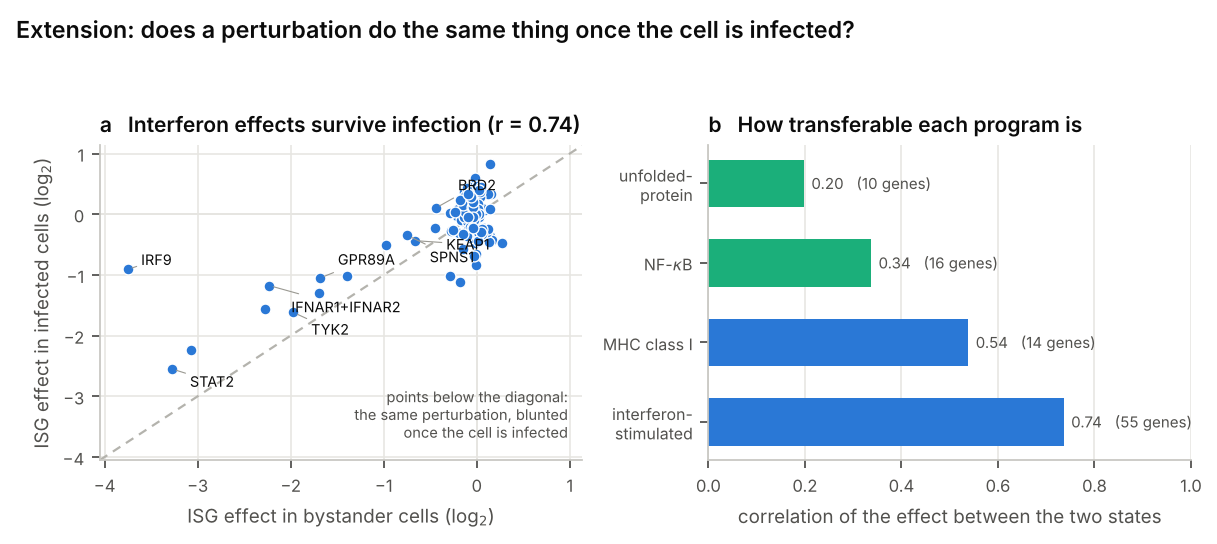

In [10]:
pt = M.table("06_program_scores_by_state.tsv")
tab = M.table("06_state_specific_effects.tsv")

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.4))

ax = axes[0]
lim = (min(pt.isg_bystander.min(), pt.isg_infected.min()) - 0.3,
       max(pt.isg_bystander.max(), pt.isg_infected.max()) + 0.3)
ax.plot(lim, lim, color=NEUTRAL, linewidth=1.0, linestyle=(0, (4, 3)), zorder=1)
ax.axhline(0, color=GRID, linewidth=0.8)
ax.axvline(0, color=GRID, linewidth=0.8)
ax.scatter(pt.isg_bystander, pt.isg_infected, s=24, color=BLUE,
           edgecolor="white", linewidth=0.6, zorder=3)
offs = {"IRF9": (6, 2), "STAT2": (8, -8), "IFNAR1+IFNAR2": (10, -12),
        "TYK2": (8, -10), "GPR89A": (8, 6), "SPNS1": (10, -12),
        "KEAP1": (14, -4), "BRD2": (10, 8)}
for tgt, off in offs.items():
    row = pt[pt.target == tgt]
    if len(row):
        ax.annotate(tgt, (row.isg_bystander.iloc[0], row.isg_infected.iloc[0]),
                    textcoords="offset points", xytext=off, fontsize=6.5, color=INK,
                    arrowprops=dict(arrowstyle="-", color="#9a9992", lw=0.5,
                                    shrinkA=0, shrinkB=2))
r = float(np.corrcoef(pt.isg_bystander, pt.isg_infected)[0, 1])
style(ax, grid_axis="both")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("ISG effect in bystander cells (log$_2$)")
ax.set_ylabel("ISG effect in infected cells (log$_2$)")
ax.set_title(f"a   Interferon effects survive infection (r = {r:.2f})", loc="left")
ax.annotate("points below the diagonal:\nthe same perturbation, blunted\nonce the cell is infected",
            xy=(0.97, 0.06), xycoords="axes fraction", ha="right", va="bottom",
            fontsize=6.6, color=INK2)

ax = axes[1]
progs = ["isg", "mhc_class_i", "nfkb", "unfolded_protein"]
names = ["interferon-\nstimulated", "MHC class I", "NF-$\\kappa$B", "unfolded-\nprotein"]
rs, ns = [], []
for p in progs:
    sub = pt[[f"{p}_bystander", f"{p}_infected"]].dropna()
    rs.append(float(np.corrcoef(sub.iloc[:, 0], sub.iloc[:, 1])[0, 1]))
    ns.append(int(pt[f"{p}_n_genes"].iloc[0]))
y = np.arange(len(progs))
ax.barh(y, rs, color=[BLUE, BLUE, AQUA, AQUA], height=0.6, linewidth=0)
for i, (v, n) in enumerate(zip(rs, ns)):
    ax.text(v + 0.015, i, f"{v:.2f}   ({n} genes)", va="center", fontsize=6.8, color=INK2)
ax.set_yticks(y)
ax.set_yticklabels(names, fontsize=7.2)
style(ax, grid_axis="x")
ax.set_xlim(0, 1.0)
ax.set_xlabel("correlation of the effect between the two states")
ax.set_title("b   How transferable each program is", loc="left")

fig.suptitle("Extension: does a perturbation do the same thing once the cell is infected?",
             x=0.005, ha="left", fontsize=10.5, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(M.FIGURES / "infection_state.png")
plt.show()